# Proyecto: Segmentación de videojuegos con K-Means

Dataset: Video Game Sales with Ratings (Kaggle)

## Parte 1. Tema y planteamiento del problema

**Tema:** ventas y calificaciones de videojuegos.

**Problema:** normalmente los videojuegos se clasifican por género o por consola, pero eso no dice nada de si el juego vendió bien o si a la gente le gustó. Hay juegos que venden millones aunque tengan malas críticas y otros muy buenos que casi nadie compró. También hay juegos que solo se venden bien en Japón. La idea es agrupar los juegos según cómo les fue en ventas y calificaciones para ver qué tipos de juegos hay.

**Objetivo general:** agrupar videojuegos con K-Means usando sus ventas, sus calificaciones y la región donde más venden, para encontrar perfiles de juegos que sirvan para tomar decisiones.

**Objetivos específicos:**
1. Explorar y limpiar el dataset.
2. Probar varios valores de K y elegir el mejor con el método del codo y la silueta.
3. Interpretar los grupos y ponerles un nombre.
4. Hacer un dashboard para ver los resultados.

**Justificación:** la industria de los videojuegos mueve mucho dinero y saber qué tipo de juegos venden más (y cuáles no) le sirve a las empresas para decidir en qué invertir y dónde vender sus juegos.

**Qué esperamos encontrar:** un grupo de juegos muy vendidos, uno de juegos buenos que vendieron poco, uno de juegos que venden más en Japón y uno de juegos con malas calificaciones.

## Parte 2. Obtención y exploración del dataset

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

Fuente: Kaggle, "Video Game Sales with Ratings" de rush4ratio
https://www.kaggle.com/datasets/rush4ratio/video-game-sales-with-ratings

Tiene datos de ventas de VGChartz y calificaciones de Metacritic hasta diciembre de 2016. Las ventas están en millones de copias.

In [2]:
df_original = pd.read_csv("../data/raw/Video_Games_Sales_as_at_22_Dec_2016.csv")
df_original.head(10)

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26,NaN,NaN,NaN,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.28,9.14,6.50,2.88,29.80,89.0,65.0,8.5,431.0,Nintendo,E
7,Wii Play,Wii,2006.0,Misc,Nintendo,13.96,9.18,2.93,2.84,28.92,58.0,41.0,6.6,129.0,Nintendo,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,Nintendo,14.44,6.94,4.70,2.24,28.32,87.0,80.0,8.4,594.0,Nintendo,E
9,Duck Hunt,NES,1984.0,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Filas y columnas:", df_original.shape)
df_original.info()

Filas y columnas: (16719, 16)
<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  str    
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(9), str(7)
memory usage: 3.0

Columnas importantes:
- Name, Platform, Year_of_Release, Genre, Publisher: datos generales del juego
- NA_Sales, EU_Sales, JP_Sales, Other_Sales: ventas por región (Norteamérica, Europa, Japón y otros)
- Global_Sales: ventas totales
- Critic_Score: calificación de la crítica (0 a 100)
- User_Score: calificación de los usuarios (0 a 10)
- Critic_Count y User_Count: cuántas personas calificaron
- Rating: clasificación ESRB

User_Score aparece como texto (object) aunque deberían ser números, eso se revisa más adelante.

In [4]:
df_original.describe()

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Count
count,16450.000000,16719.000000,16719.000000,16719.000000,16719.000000,16719.000000,8137.000000,8137.000000,7590.000000
mean,2006.487356,0.263330,0.145025,0.077602,0.047332,0.533543,68.967679,26.360821,162.229908
std,5.878995,0.813514,0.503283,0.308818,0.186710,1.547935,13.938165,18.980495,561.282326
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000,13.000000,3.000000,4.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000,60.000000,12.000000,10.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000,71.000000,21.000000,24.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,0.470000,79.000000,36.000000,81.000000
max,2020.000000,41.360000,28.960000,10.220000,10.570000,82.530000,98.000000,113.000000,10665.000000


In [5]:
print("Valores nulos por columna:")
print(df_original.isnull().sum())
print()
print("Registros duplicados:", df_original.duplicated().sum())
print("Duplicados por nombre y plataforma:", df_original.duplicated(subset=["Name", "Platform"]).sum())

Valores nulos por columna:
Name                  2
Platform              0
Year_of_Release     269
Genre                 2
Publisher            54
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score       8582
Critic_Count       8582
User_Score         6704
User_Count         9129
Developer          6623
Rating             6769
dtype: int64

Registros duplicados: 0
Duplicados por nombre y plataforma: 5


In [6]:
# por qué User_Score es texto
print(df_original["User_Score"].unique()[:30])
print("Cantidad de 'tbd':", (df_original["User_Score"] == "tbd").sum())

<ArrowStringArray>
[  '8',   nan, '8.3', '8.5', '6.6', '8.4', '8.6', '7.7', '6.3', '7.4', '8.2',
   '9', '7.9', '8.1', '8.7', '7.1', '3.4', '5.3', '4.8', '3.2', '8.9', '6.4',
 '7.8', '7.5', '2.6', '7.2', '9.2',   '7', '7.3', '4.3']
Length: 30, dtype: str
Cantidad de 'tbd': 2425


Hay muchos nulos en las calificaciones (más de la mitad) y además User_Score tiene el texto 'tbd' (to be determined) en 2,425 filas.

### Gráficas exploratorias

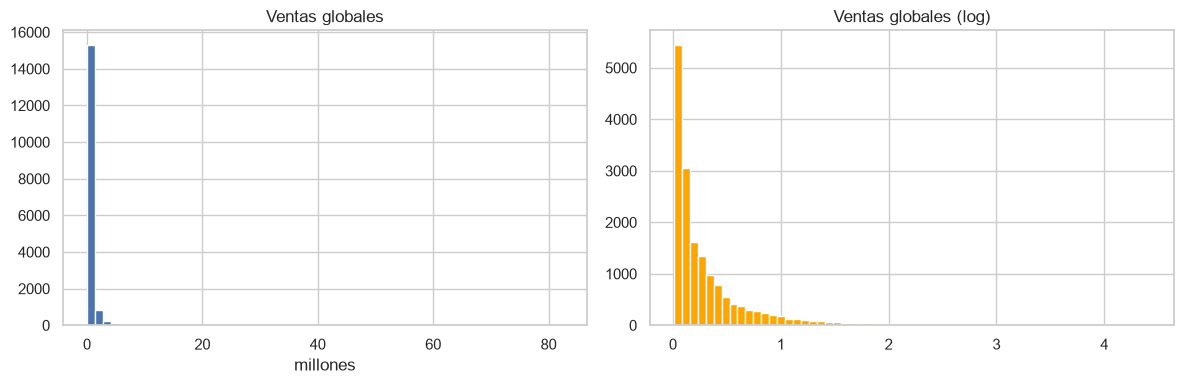

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_original["Global_Sales"], bins=60)
ax[0].set_title("Ventas globales")
ax[0].set_xlabel("millones")
ax[1].hist(np.log1p(df_original["Global_Sales"]), bins=60, color="orange")
ax[1].set_title("Ventas globales (log)")
plt.tight_layout()
plt.show()

Casi todos los juegos venden menos de 1 millón y muy pocos venden más de 20 millones. Con logaritmo la gráfica se ve mucho mejor repartida.

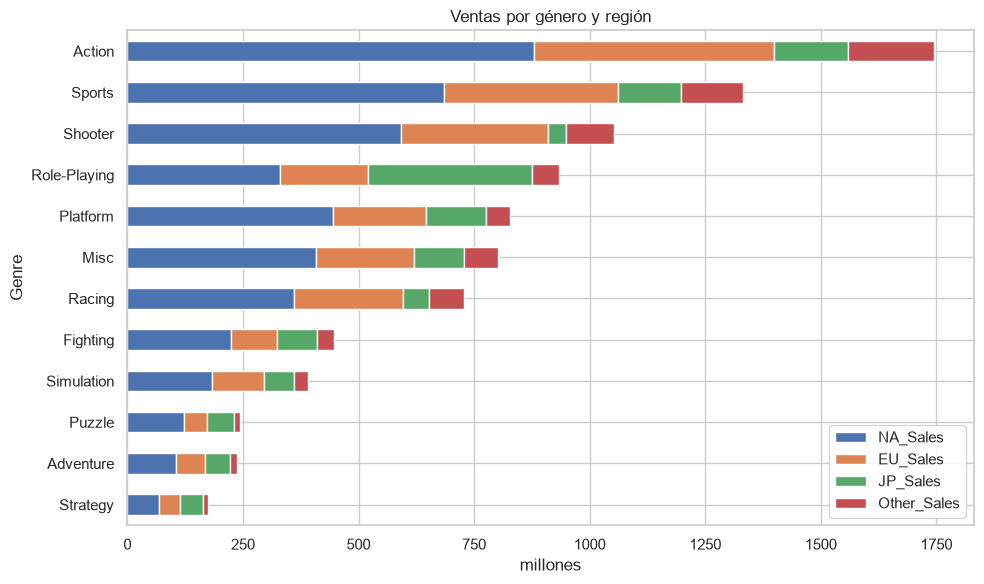

In [8]:
ventas_genero = df_original.groupby("Genre")[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
ventas_genero["total"] = ventas_genero.sum(axis=1)
ventas_genero = ventas_genero.sort_values("total").drop(columns="total")
ventas_genero.plot(kind="barh", stacked=True, figsize=(10, 6))
plt.title("Ventas por género y región")
plt.xlabel("millones")
plt.tight_layout()
plt.show()

Action, Sports y Shooter son los que más venden, sobre todo en Norteamérica. En Japón se nota que vende más Role-Playing que los demás.

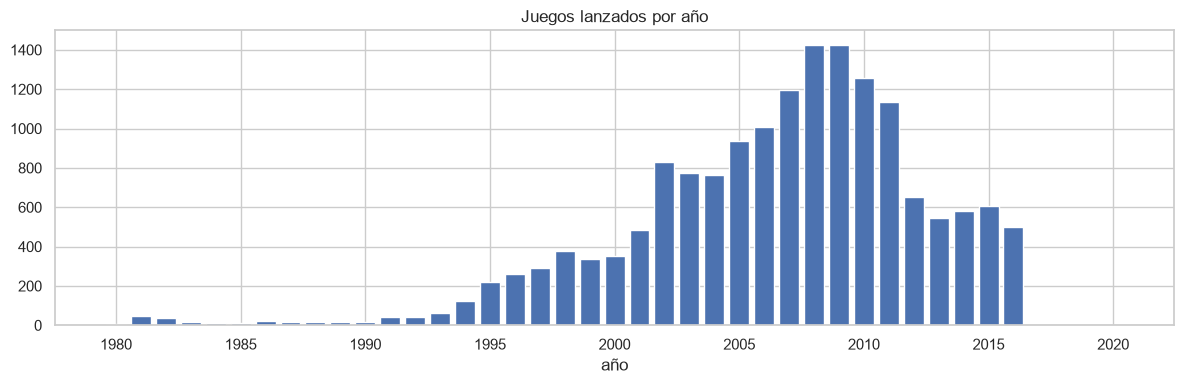

In [9]:
juegos_anio = df_original.groupby("Year_of_Release")["Name"].count()
plt.figure(figsize=(12, 4))
plt.bar(juegos_anio.index, juegos_anio.values)
plt.title("Juegos lanzados por año")
plt.xlabel("año")
plt.tight_layout()
plt.show()

La mayoría de los juegos salieron entre 2005 y 2011. Después de 2016 casi no hay datos.

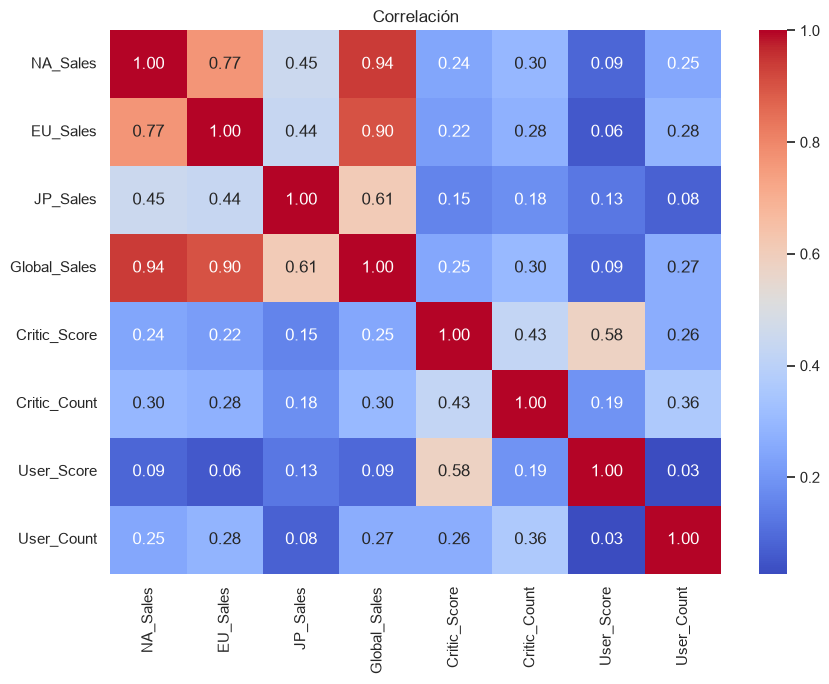

In [10]:
temp = df_original.copy()
temp["User_Score"] = pd.to_numeric(temp["User_Score"], errors="coerce")
columnas = ["NA_Sales", "EU_Sales", "JP_Sales", "Global_Sales", "Critic_Score", "Critic_Count", "User_Score", "User_Count"]
plt.figure(figsize=(9, 7))
sns.heatmap(temp[columnas].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación")
plt.tight_layout()
plt.show()

### Variables elegidas para el modelo

- **Critic_Score:** para saber qué tan bueno es el juego según la crítica.
- **User_Score:** la opinión de los jugadores. Tiene relación con la crítica (0.58) pero no es igual, así que vale la pena usar las dos.
- **Global_Sales:** para medir qué tanto vendió. Se va a usar con logaritmo porque está muy sesgada.
- **JP_Share:** es una variable nueva = JP_Sales / Global_Sales. Sirve para saber qué parte de las ventas fue en Japón.

No usamos NA_Sales ni EU_Sales porque están muy correlacionadas con Global_Sales (0.94 y 0.90) y repetirían la misma información.

## Parte 3. Limpieza y preparación de datos

In [11]:
df = df_original.copy()
print("Filas al inicio:", len(df))

# 'tbd' no es un número, se cambia por nulo y se convierte la columna
df["User_Score"] = df["User_Score"].replace("tbd", np.nan)
df["User_Score"] = pd.to_numeric(df["User_Score"])

# juegos sin nombre o sin género
df = df.dropna(subset=["Name", "Genre"])
print("Sin nombre/género:", len(df))

# duplicados
df = df.drop_duplicates(subset=["Name", "Platform", "Year_of_Release"])
print("Sin duplicados:", len(df))

# sin año
df = df.dropna(subset=["Year_of_Release"])
print("Sin nulos en año:", len(df))

# sin calificaciones
df = df.dropna(subset=["Critic_Score", "User_Score"])
print("Sin nulos en calificaciones:", len(df))

Filas al inicio: 16719
Sin nombre/género: 16717
Sin duplicados: 16716
Sin nulos en año: 16447
Sin nulos en calificaciones: 6893


Las filas sin calificación se eliminaron en lugar de rellenarlas. Son más de la mitad del dataset, y si les poníamos el promedio íbamos a estar inventando la calificación de muchos juegos. Aun así quedan 6,893 juegos, que es suficiente.

In [12]:
# tipos de datos
df["Year_of_Release"] = df["Year_of_Release"].astype(int)
df["Critic_Count"] = df["Critic_Count"].astype(int)
df["User_Count"] = df["User_Count"].astype(int)

# Rating: K-A es la clasificación vieja de E, y las que casi no aparecen se juntan
df["Rating"] = df["Rating"].replace("K-A", "E")
df.loc[~df["Rating"].isin(["E", "E10+", "T", "M"]), "Rating"] = "Otro"
df["Developer"] = df["Developer"].fillna("Desconocido")
df["Publisher"] = df["Publisher"].fillna("Desconocido")

print(df["Rating"].value_counts())
print(df.dtypes)

Rating
T       2378
E       2082
M       1433
E10+     930
Otro      70
Name: count, dtype: int64
Name                   str
Platform               str
Year_of_Release      int64
Genre                  str
Publisher              str
NA_Sales           float64
EU_Sales           float64
JP_Sales           float64
Other_Sales        float64
Global_Sales       float64
Critic_Score       float64
Critic_Count         int64
User_Score         float64
User_Count           int64
Developer              str
Rating                 str
dtype: object


In [13]:
# columna de fabricante para no tener 31 plataformas en los filtros
nintendo = ["Wii", "WiiU", "DS", "3DS", "GBA", "GC", "N64"]
sony = ["PS", "PS2", "PS3", "PS4", "PSP", "PSV"]
microsoft = ["XB", "X360", "XOne"]

def fabricante(plataforma):
    if plataforma in nintendo:
        return "Nintendo"
    if plataforma in sony:
        return "Sony"
    if plataforma in microsoft:
        return "Microsoft"
    if plataforma == "PC":
        return "PC"
    return "Sega"

df["Fabricante"] = df["Platform"].apply(fabricante)
df["Fabricante"].value_counts()

Fabricante
Sony         2824
Nintendo     1775
Microsoft    1592
PC            688
Sega           14
Name: count, dtype: int64

In [14]:
# revisar inconsistencias
suma_regiones = df["NA_Sales"] + df["EU_Sales"] + df["JP_Sales"] + df["Other_Sales"]
print("Juegos donde la suma de regiones no coincide con Global_Sales:", ((df["Global_Sales"] - suma_regiones).abs() > 0.02).sum())
print("Calificaciones fuera de rango:", ((df["Critic_Score"] > 100) | (df["User_Score"] > 10)).sum())
print("Juegos con ventas en 0:", (df["Global_Sales"] == 0).sum())

Juegos donde la suma de regiones no coincide con Global_Sales: 3
Calificaciones fuera de rango: 0
Juegos con ventas en 0: 0


Solo 3 juegos tienen una diferencia pequeña en la suma de ventas (por redondeo), así que se dejaron igual.

### Valores atípicos

In [15]:
for col in ["Global_Sales", "Critic_Score", "User_Score"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    atipicos = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, "->", len(atipicos), "atípicos")

Global_Sales -> 681 atípicos
Critic_Score -> 106 atípicos
User_Score -> 266 atípicos


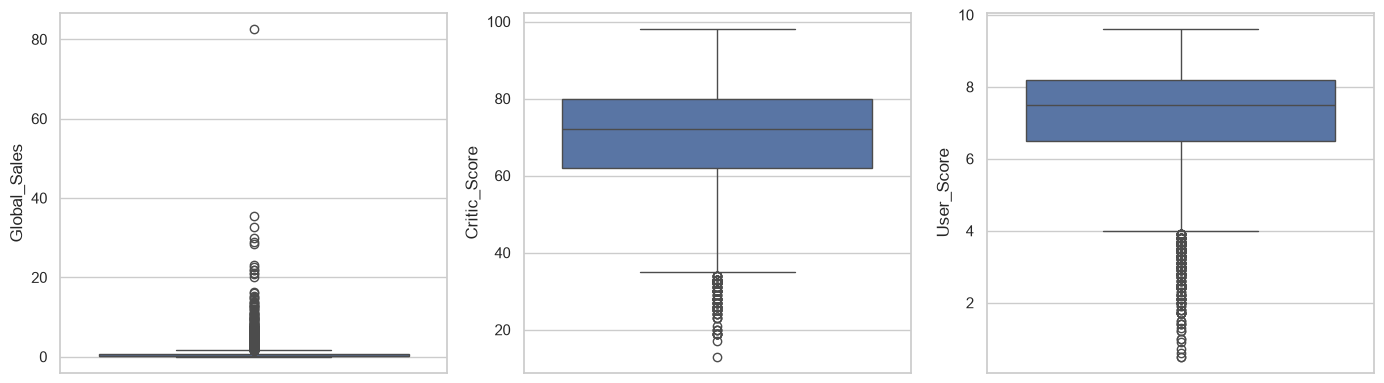

,Name,Platform,Global_Sales
0,Wii Sports,Wii,82.53
2,Mario Kart Wii,Wii,35.52
3,Wii Sports Resort,Wii,32.77
6,New Super Mario Bros.,DS,29.80
7,Wii Play,Wii,28.92


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=df["Global_Sales"], ax=ax[0])
sns.boxplot(y=df["Critic_Score"], ax=ax[1])
sns.boxplot(y=df["User_Score"], ax=ax[2])
plt.tight_layout()
plt.show()

df.sort_values("Global_Sales", ascending=False)[["Name", "Platform", "Global_Sales"]].head()

Los atípicos de ventas no se eliminaron porque son juegos reales como Wii Sports o Mario Kart, y justo esos son los que nos interesa encontrar. Lo que se hizo fue aplicar logaritmo a las ventas para que no afecten tanto al modelo. Los atípicos de calificación son juegos con notas muy bajas, también son reales y se quedan.

### Transformaciones y escalamiento

In [17]:
df["Log_Sales"] = np.log1p(df["Global_Sales"])
df["JP_Share"] = df["JP_Sales"] / df["Global_Sales"]
df["User_Score_100"] = df["User_Score"] * 10  # para que quede de 0 a 100 igual que la crítica

variables = ["Critic_Score", "User_Score_100", "Log_Sales", "JP_Share"]
scaler = StandardScaler()
X = scaler.fit_transform(df[variables])

print("Antes de escalar:")
print(df[variables].describe().round(2))
print()
print("Después de escalar:")
print(pd.DataFrame(X, columns=variables).describe().round(2))

Antes de escalar:
       Critic_Score  User_Score_100  Log_Sales  JP_Share
count       6893.00         6893.00    6893.00   6893.00
mean          70.26           71.85       0.41      0.07
std           13.86           14.40       0.46      0.18
min           13.00            5.00       0.01      0.00
25%           62.00           65.00       0.10      0.00
50%           72.00           75.00       0.25      0.00
75%           80.00           82.00       0.56      0.02
max           98.00           96.00       4.43      1.00

Después de escalar:
       Critic_Score  User_Score_100  Log_Sales  JP_Share
count       6893.00         6893.00    6893.00   6893.00
mean          -0.00           -0.00       0.00     -0.00
std            1.00            1.00       1.00      1.00
min           -4.13           -4.64      -0.89     -0.39
25%           -0.60           -0.48      -0.68     -0.39
50%            0.13            0.22      -0.35     -0.39
75%            0.70            0.71       0.32   

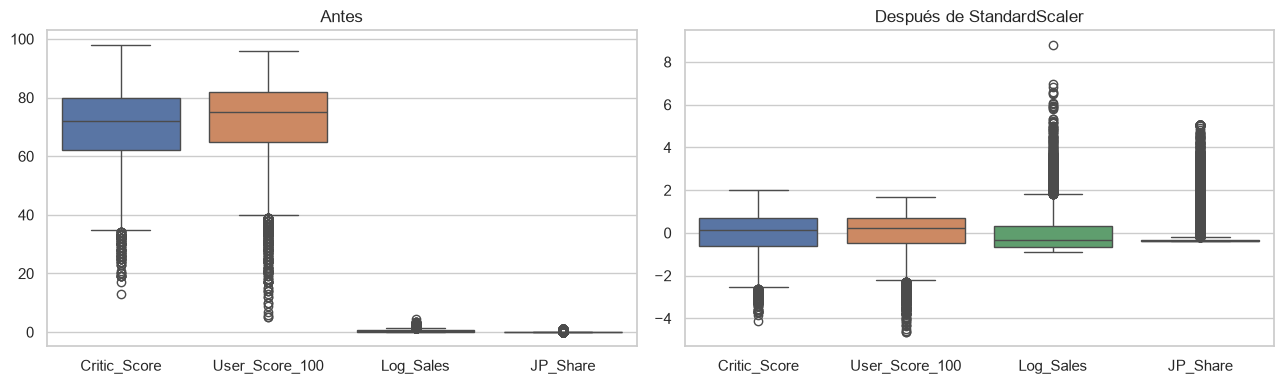

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df[variables], ax=ax[0])
ax[0].set_title("Antes")
sns.boxplot(data=pd.DataFrame(X, columns=variables), ax=ax[1])
ax[1].set_title("Después de StandardScaler")
plt.tight_layout()
plt.show()

Escalar es necesario porque K-Means usa distancias. Critic_Score va de 0 a 100 y JP_Share de 0 a 1, entonces sin escalar la crítica pesaría muchísimo más que la otra variable. Con StandardScaler todas quedan con media 0 y desviación 1.

## Parte 4. K-Means

In [19]:
inercias = []
siluetas = []
davies = []
valores_k = range(2, 11)

for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, etiquetas))
    davies.append(davies_bouldin_score(X, etiquetas))

evaluacion = pd.DataFrame({"K": valores_k, "Inercia": inercias, "Silueta": siluetas, "Davies-Bouldin": davies})
evaluacion.round(3)

,K,Inercia,Silueta,Davies-Bouldin
0,2,19986.660,0.284,1.293
1,3,14961.538,0.334,1.053
2,4,10964.562,0.356,0.941
3,5,9400.109,0.289,1.045
4,6,8449.245,0.275,1.086
5,7,7631.173,0.281,1.084
6,8,6891.974,0.285,1.072
7,9,6354.244,0.258,1.076
8,10,5985.896,0.260,1.093


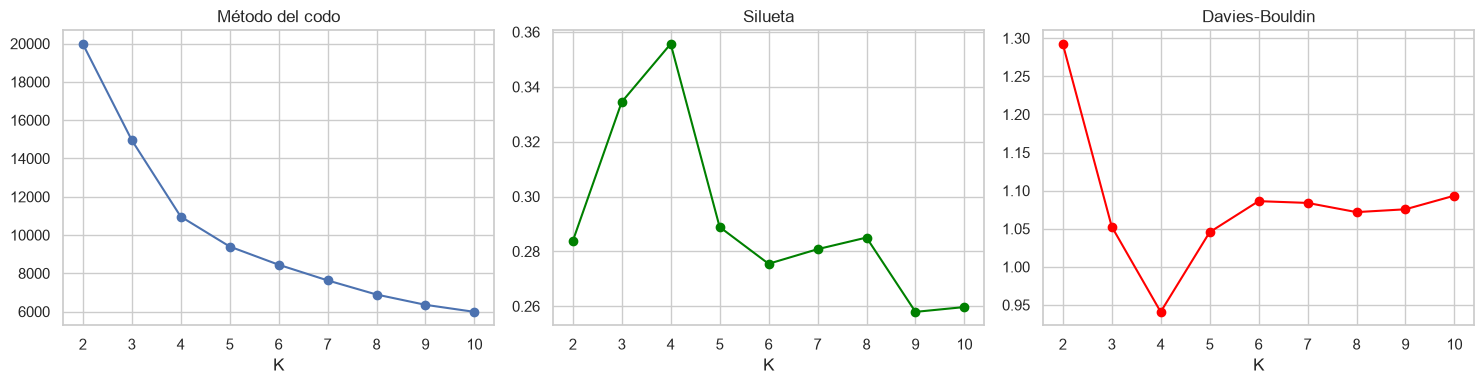

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(valores_k, inercias, marker="o")
ax[0].set_title("Método del codo")
ax[1].plot(valores_k, siluetas, marker="o", color="green")
ax[1].set_title("Silueta")
ax[2].plot(valores_k, davies, marker="o", color="red")
ax[2].set_title("Davies-Bouldin")
for a in ax:
    a.set_xlabel("K")
plt.tight_layout()
plt.show()

Elegimos **K = 4**. Es el que tiene la silueta más alta (0.356) y el Davies-Bouldin más bajo (0.941), y en la gráfica del codo es donde la curva empieza a bajar más lento.

In [21]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X)

centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=variables)
centroides["Ventas"] = np.expm1(centroides["Log_Sales"])
centroides["User_Score"] = centroides["User_Score_100"] / 10
centroides[["Critic_Score", "User_Score", "Ventas", "JP_Share"]].round(2)

,Critic_Score,User_Score,Ventas,JP_Share
0,74.21,7.75,0.31,0.02
1,71.37,7.76,0.41,0.60
2,82.91,7.75,2.59,0.06
3,53.21,5.36,0.26,0.01


Viendo los centroides (ya regresados a sus unidades originales):
- Cluster 0: crítica de 74 y usuarios 7.7, pero vende poco (0.31 millones).
- Cluster 1: el 60% de sus ventas son en Japón.
- Cluster 2: la mejor crítica (83) y el que más vende (2.6 millones).
- Cluster 3: calificaciones bajas (53 y 5.4).

Con eso les pusimos nombre a los grupos:

In [22]:
nombres = {
    0: "Buenos con pocas ventas",
    1: "Populares en Japón",
    2: "Superventas",
    3: "Mal calificados",
}
df["Grupo"] = df["Cluster"].map(nombres)
centroides.index = centroides.index.map(nombres)
centroides[["Critic_Score", "User_Score", "Ventas", "JP_Share"]].round(2)

,Critic_Score,User_Score,Ventas,JP_Share
Buenos con pocas ventas,74.21,7.75,0.31,0.02
Populares en Japón,71.37,7.76,0.41,0.60
Superventas,82.91,7.75,2.59,0.06
Mal calificados,53.21,5.36,0.26,0.01


In [23]:
print(df["Grupo"].value_counts())
print()
print((df["Grupo"].value_counts(normalize=True) * 100).round(1))

Grupo
Buenos con pocas ventas    3676
Mal calificados            1637
Superventas                1005
Populares en Japón          575
Name: count, dtype: int64

Grupo
Buenos con pocas ventas    53.3
Mal calificados            23.7
Superventas                14.6
Populares en Japón          8.3
Name: proportion, dtype: float64


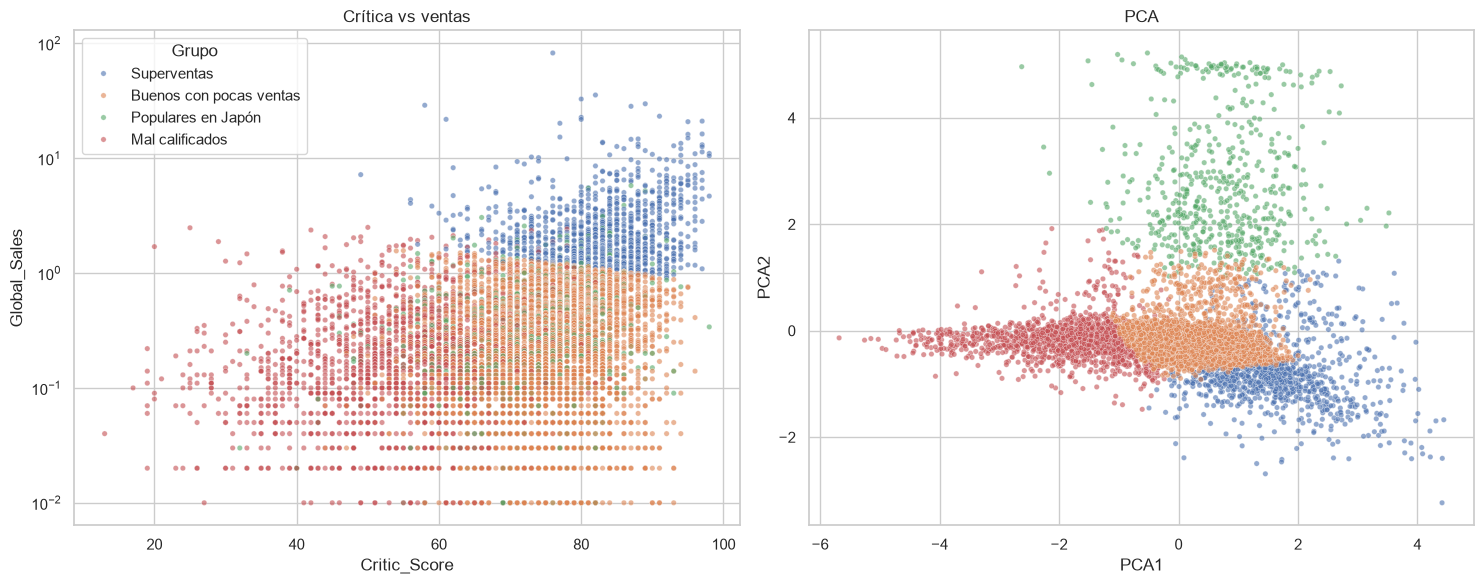

Varianza explicada por PCA: 0.7


In [24]:
pca = PCA(n_components=2)
componentes = pca.fit_transform(X)
df["PCA1"] = componentes[:, 0]
df["PCA2"] = componentes[:, 1]

orden = ["Superventas", "Buenos con pocas ventas", "Populares en Japón", "Mal calificados"]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=df, x="Critic_Score", y="Global_Sales", hue="Grupo", hue_order=orden, s=15, alpha=0.6, ax=ax[0])
ax[0].set_yscale("log")
ax[0].set_title("Crítica vs ventas")
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Grupo", hue_order=orden, s=15, alpha=0.6, ax=ax[1], legend=False)
ax[1].set_title("PCA")
plt.tight_layout()
plt.show()
print("Varianza explicada por PCA:", pca.explained_variance_ratio_.sum().round(2))

### Comparación con otra configuración (K = 5)

In [25]:
kmeans5 = KMeans(n_clusters=5, n_init=10, random_state=42)
df["Cluster_K5"] = kmeans5.fit_predict(X)

print("K=4  silueta:", round(silhouette_score(X, df["Cluster"]), 3), " davies-bouldin:", round(davies_bouldin_score(X, df["Cluster"]), 3), " inercia:", round(kmeans.inertia_))
print("K=5  silueta:", round(silhouette_score(X, df["Cluster_K5"]), 3), " davies-bouldin:", round(davies_bouldin_score(X, df["Cluster_K5"]), 3), " inercia:", round(kmeans5.inertia_))

centroides5 = pd.DataFrame(scaler.inverse_transform(kmeans5.cluster_centers_), columns=variables)
print(centroides5.round(2))
pd.crosstab(df["Grupo"], df["Cluster_K5"])

K=4  silueta: 0.356  davies-bouldin: 0.941  inercia: 10965


K=5  silueta: 0.289  davies-bouldin: 1.045  inercia: 9400
   Critic_Score  User_Score_100  Log_Sales  JP_Share
0         82.90           76.86       1.35      0.06
1         47.16           43.28       0.21      0.01
2         78.53           80.69       0.31      0.02
3         71.30           77.57       0.34      0.61
4         62.88           67.58       0.25      0.02


Cluster_K5,0,1,2,3,4
Grupo,,,,,
Buenos con pocas ventas,0,0,2440,4,1232
Mal calificados,2,744,0,0,891
Populares en Japón,1,0,7,562,5
Superventas,870,0,126,0,9


Con K = 5 la inercia baja, pero eso pasa siempre que se agregan más grupos. La silueta baja de 0.356 a 0.289 y el Davies-Bouldin sube, o sea que los grupos quedan menos separados. En la tabla se ve que lo que hace K = 5 es partir el grupo de "Buenos con pocas ventas" en dos (uno con calificaciones un poco más bajas) y mover parte de los mal calificados a ese grupo nuevo. No aparece un tipo de juego realmente diferente, por eso nos quedamos con K = 4.

## Parte 5. Análisis de resultados

In [26]:
df.groupby("Grupo")[["Global_Sales", "Critic_Score", "User_Score", "JP_Share", "User_Count"]].describe().T.round(2)

Grupo               Buenos con pocas ventas  Mal calificados  \
Global_Sales count                  3676.00          1637.00   
             mean                      0.35             0.29   
             std                       0.31             0.36   
             min                       0.01             0.01   
             25%                       0.10             0.08   
             50%                       0.24             0.17   
             75%                       0.52             0.35   
             max                       1.57             2.50   
Critic_Score count                  3676.00          1637.00   
             mean                     74.21            53.21   
             std                       8.71            11.81   
             min                      44.00            13.00   
             25%                      68.00            46.00   
             50%                      75.00            54.00   
             75%                      81.00            61.00   
             max                      96.00            86.00   
User_Score   count                  3676.00          1637.00   
             mean                      7.75             5.36   
             std                       0.81             1.37   
             min                       4.50             0.50   
             25%                       7.20             4.60   
             50%                       7.80             5.60   
             75%                       8.40             6.30   
             max                       9.60             8.90   
JP_Share     count                  3676.00          1637.00   
             mean                      0.02             0.01   
             std                       0.06             0.05   
             min                       0.00             0.00   
             25%                       0.00             0.00   
             50%                       0.00             0.00   
             75%                       0.00             0.00   
             max                       0.32             0.39   
User_Count   count                  3676.00          1637.00   
             mean                    124.53            88.17   
             std                     434.10           416.16   
             min                       4.00             4.00   
             25%                      11.00             7.00   
             50%                      24.00            14.00   
             75%                      73.00            35.00   
             max                   10665.00          6430.00   

Grupo               Populares en Japón  Superventas  
Global_Sales count              575.00      1005.00  
             mean                 0.48         3.28  
             std                  0.61         4.25  
             min                  0.01         0.91  
             25%                  0.14         1.49  
             50%                  0.29         2.11  
             75%                  0.61         3.49  
             max                  5.78        82.53  
Critic_Score count              575.00      1005.00  
             mean                71.37        82.91  
             std                 10.26         7.87  
             min                 32.00        49.00  
             25%                 65.00        79.00  
             50%                 72.00        84.00  
             75%                 79.00        89.00  
             max                 98.00        98.00  
User_Score   count              575.00      1005.00  
             mean                 7.76         7.75  
             std                  0.91         1.08  
             min                  3.00         2.60  
             25%                  7.30         7.30  
             50%                  7.90         8.00  
             75%                  8.40         8.50  
             max                  9.40         9.50  
JP_Share     count       

In [27]:
tabla = df.groupby("Grupo").agg(
    juegos=("Name", "count"),
    ventas_promedio=("Global_Sales", "mean"),
    ventas_mediana=("Global_Sales", "median"),
    ventas_totales=("Global_Sales", "sum"),
    critica=("Critic_Score", "mean"),
    usuarios=("User_Score", "mean"),
    porcentaje_japon=("JP_Share", "mean"),
)
tabla["porcentaje_japon"] = tabla["porcentaje_japon"] * 100
tabla["porcentaje_ventas"] = tabla["ventas_totales"] / tabla["ventas_totales"].sum() * 100
tabla = tabla.loc[orden]
tabla.round(2)

,juegos,ventas_promedio,ventas_mediana,ventas_totales,critica,usuarios,porcentaje_japon,porcentaje_ventas
Grupo,,,,,,,,
Superventas,1005,3.28,2.11,3294.73,82.91,7.75,5.98,61.95
Buenos con pocas ventas,3676,0.35,0.24,1268.41,74.21,7.75,1.91,23.85
Populares en Japón,575,0.48,0.29,276.75,71.37,7.76,60.40,5.20
Mal calificados,1637,0.29,0.17,478.73,53.21,5.36,1.40,9.00


In [28]:
for g in orden:
    print(g)
    print("  género más común:", df[df["Grupo"] == g]["Genre"].value_counts().index[0])
    print("  más vendidos:", list(df[df["Grupo"] == g].sort_values("Global_Sales", ascending=False)["Name"].head(5)))

Superventas
  género más común: Action
  más vendidos: ['Wii Sports', 'Mario Kart Wii', 'Wii Sports Resort', 'New Super Mario Bros.', 'Wii Play']
Buenos con pocas ventas
  género más común: Action
  más vendidos: ['Conflict: Desert Storm', 'Pokemon Mystery Dungeon: Explorers of Sky', 'Star Wars: The Force Unleashed II', '007: Quantum of Solace', 'Sonic Rivals 2']
Populares en Japón
  género más común: Role-Playing
  más vendidos: ['Dragon Quest IX: Sentinels of the Starry Skies', 'Monster Hunter Freedom Unite', 'Dragon Quest VIII: Journey of the Cursed King', 'Monster Hunter 4 Ultimate', 'Rhythm Heaven']
Mal calificados
  género más común: Action
  más vendidos: ['Deca Sports', 'Game Party', 'Call of Duty: Infinite Warfare', 'Zumba Fitness', 'Kinect: Disneyland Adventures']


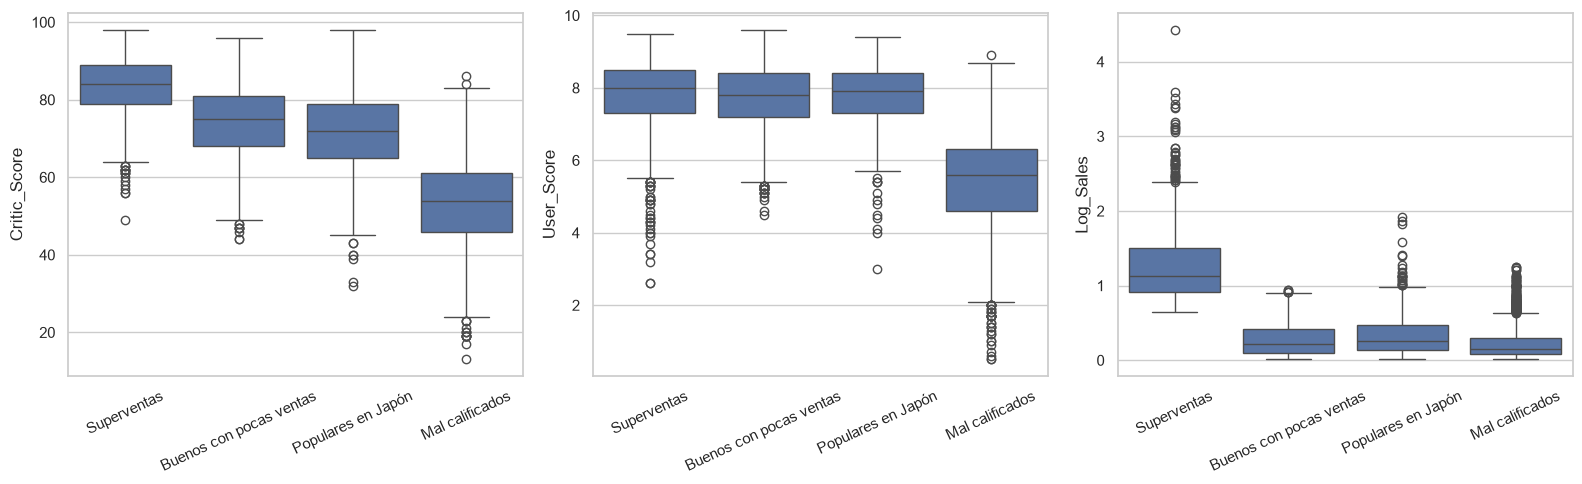

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(data=df, x="Grupo", y="Critic_Score", order=orden, ax=ax[0])
sns.boxplot(data=df, x="Grupo", y="User_Score", order=orden, ax=ax[1])
sns.boxplot(data=df, x="Grupo", y="Log_Sales", order=orden, ax=ax[2])
for a in ax:
    a.tick_params(axis="x", rotation=25)
    a.set_xlabel("")
plt.tight_layout()
plt.show()

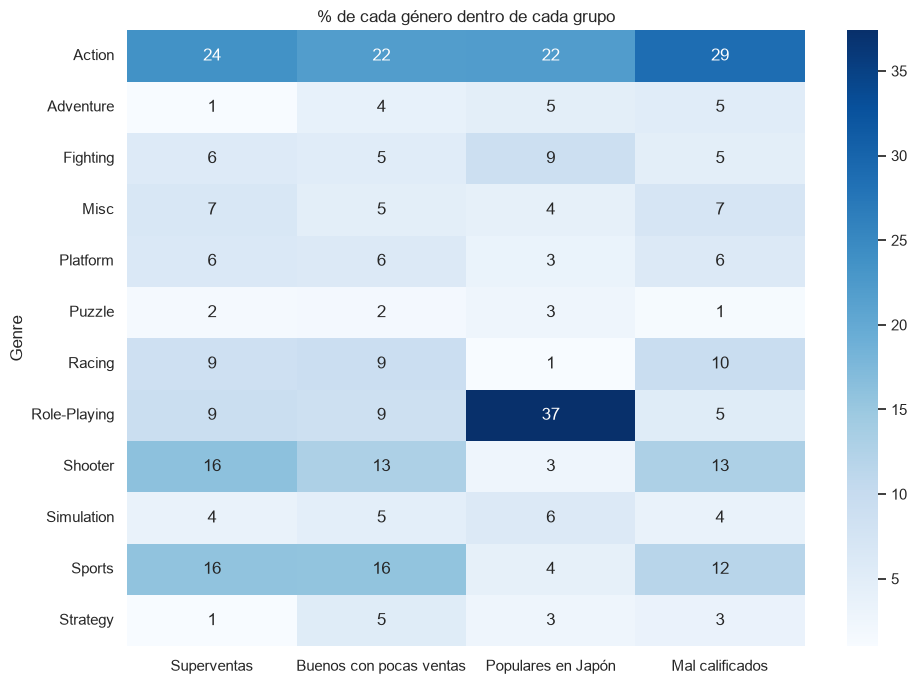

In [30]:
generos = pd.crosstab(df["Genre"], df["Grupo"], normalize="columns")[orden] * 100
plt.figure(figsize=(10, 7))
sns.heatmap(generos, annot=True, fmt=".0f", cmap="Blues")
plt.title("% de cada género dentro de cada grupo")
plt.xlabel("")
plt.tight_layout()
plt.show()

### Descripción de los grupos

**Superventas (1,005 juegos):** son los que más venden por mucho, con mediana de 2.11 millones, y también tienen la mejor crítica (83 en promedio). Aquí están Wii Sports, Mario Kart, New Super Mario Bros. y juegos como GTA o Call of Duty.

**Buenos con pocas ventas (3,676 juegos):** es el grupo más grande. La calificación de usuarios es la misma que la de los superventas (7.75), pero la mediana de ventas es de solo 0.24 millones. Son juegos que a la gente le gustaron pero no se vendieron mucho.

**Populares en Japón (575 juegos):** en promedio el 60% de sus ventas son en Japón, mientras que en los otros grupos no pasa del 6%. Casi todos son RPG, como Dragon Quest o Monster Hunter.

**Mal calificados (1,637 juegos):** tienen crítica de 53 y usuarios de 5.4. Hay muchos juegos de fiesta y de licencias, como Deca Sports, Game Party o Zumba Fitness.

### Hallazgos
1. Los superventas son solo el 14.6% de los juegos pero tienen el 62% de todas las ventas.
2. Que un juego sea bueno no significa que venda. Los "buenos con pocas ventas" tienen la misma calificación de usuarios que los superventas y venden casi 9 veces menos.
3. Japón funciona como un mercado aparte, con su propio grupo donde casi todo es RPG.
4. Los mal calificados venden un poco menos que los buenos, pero no tan poco como se esperaría (mediana de 0.17 contra 0.24 millones).

### Recomendaciones
1. A las empresas les conviene invertir en sus franquicias más fuertes, pero también darles más publicidad a los juegos que tienen buenas calificaciones y vendieron poco.
2. Los juegos del grupo de Japón necesitan una estrategia distinta si se quieren vender en América o Europa (traducción, publicidad, etc.).
3. Sacar juegos rápidos o de licencia con baja calidad no ayuda mucho en ventas y sí afecta la imagen de la empresa.
4. Las tiendas en línea pueden usar estos grupos para recomendar juegos buenos que son poco conocidos.

### Limitaciones
- Los datos solo llegan a 2016 y solo son ventas físicas, no digitales.
- Se quitaron más de la mitad de los juegos por no tener calificación.
- K-Means funciona mejor con grupos redondos y es sensible a los atípicos, por eso se tuvo que usar logaritmo.
- La silueta es de 0.356, o sea que los grupos están separados pero no muy marcados. La diferencia entre buenos y malos es gradual.
- Si un juego salió en varias consolas cuenta como varios registros.

### Guardar resultados

In [31]:
columnas_salida = ["Name", "Platform", "Fabricante", "Year_of_Release", "Genre", "Publisher", "Developer", "Rating",
                   "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales",
                   "Critic_Score", "Critic_Count", "User_Score", "User_Count",
                   "Log_Sales", "JP_Share", "PCA1", "PCA2", "Cluster", "Grupo"]
df[columnas_salida].to_csv("../data/processed/videojuegos_clusters.csv", index=False)
evaluacion.to_csv("../data/processed/evaluacion_k.csv", index=False)
centroides.round(4).to_csv("../data/processed/centroides.csv", index_label="Grupo")

metricas = {
    "K": 4,
    "silueta": float(silhouette_score(X, df["Cluster"])),
    "davies_bouldin": float(davies_bouldin_score(X, df["Cluster"])),
    "inercia": float(kmeans.inertia_),
    "registros_original": len(df_original),
    "registros_modelo": len(df),
}
with open("../data/processed/metricas_modelo.json", "w") as f:
    json.dump(metricas, f, indent=2)
print(metricas)

{'K': 4, 'silueta': 0.35567135395084243, 'davies_bouldin': 0.9409219860653125, 'inercia': 10964.562024593428, 'registros_original': 16719, 'registros_modelo': 6893}
